<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/dynamics_relativity/make_figures_ch06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Dynamics and Relativity* — `make_figures_ch06.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Dynamics & Relativity — Chapter 6 Figures

| Figure | Filename | Slide |
|--------|----------|-------|
| Centrifugal force geometry | `fig_centrifugal.png` | §6.3 |
| Apparent gravity / plumb line | `fig_apparent_gravity.png` | §6.3.1 |
| Rotating bucket parabola | `fig_rotating_bucket.png` | §6.3 |
| Hurricane Coriolis diagram | `fig_hurricane.png` | §6.4.1 |
| Foucault's pendulum | `fig_foucault.png` | §6.4.3 |


## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyBboxPatch
from matplotlib.patches import FancyArrowPatch
import os

os.makedirs('figures', exist_ok=True)

DARK_BG = '#1a1a2e'
BLUE    = '#7ec8e3'
YELLOW  = '#f9c74f'
GREEN   = '#90ee90'
RED     = '#e07070'
WHITE   = '#e8e8e8'
DIM     = '#888888'

def base_style(ax):
    ax.set_facecolor(DARK_BG)
    ax.tick_params(colors=DIM, labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor(DIM)
    ax.xaxis.label.set_color(WHITE)
    ax.yaxis.label.set_color(WHITE)

print('Setup complete.')


Setup complete.


## Fig 1 — Centrifugal Force Geometry (§6.3)

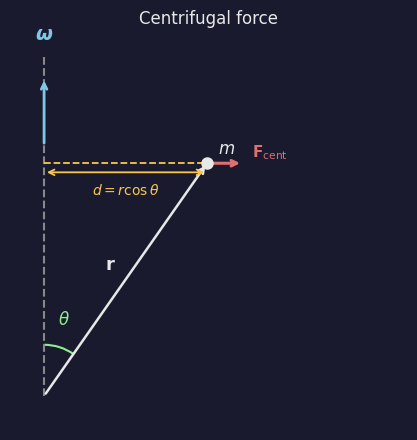

fig_centrifugal.png


In [2]:
def fig_centrifugal():
    fig, ax = plt.subplots(figsize=(4.5, 4.5), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-0.3, 3.2)
    ax.set_ylim(-0.3, 3.2)
    ax.set_aspect('equal')
    ax.axis('off')

    # Rotation axis (vertical dashed line)
    ax.plot([0, 0], [0, 3.0], '--', color=DIM, lw=1.5)
    ax.text(0, 3.1, r'$\boldsymbol{\omega}$', color=BLUE,
            fontsize=14, ha='center', va='bottom')
    ax.annotate('', xy=(0, 2.8), xytext=(0, 2.2),
                arrowprops=dict(arrowstyle='->', color=BLUE, lw=2))

    # Particle position
    theta = np.radians(35)
    r = 2.5
    px, py = r * np.sin(theta), r * np.cos(theta)

    # r vector
    ax.annotate('', xy=(px, py), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=1.8))
    ax.text(px/2 - 0.18, py/2 + 0.08, r'$\mathbf{r}$',
            color=WHITE, fontsize=13)

    # d: perpendicular distance to axis
    ax.plot([0, px], [py, py], '--', color=YELLOW, lw=1.3)
    ax.annotate('', xy=(px, py - 0.08), xytext=(0, py - 0.08),
                arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.3))
    ax.text(px/2, py - 0.28, r'$d = r\cos\theta$',
            color=YELLOW, fontsize=10, ha='center')

    # Angle theta
    arc = Arc((0, 0), 0.9, 0.9, angle=0,
              theta1=90 - np.degrees(theta), theta2=90,
              color=GREEN, lw=1.5)
    ax.add_patch(arc)
    ax.text(0.12, 0.62, r'$\theta$', color=GREEN, fontsize=12)

    # Particle
    ax.plot(px, py, 'o', color=WHITE, ms=8, zorder=5)
    ax.text(px + 0.1, py + 0.08, r'$m$', color=WHITE, fontsize=12)

    # Centrifugal force arrow (radially outward, perpendicular to axis)
    fcx, fcy = 0.55 * np.sin(theta), 0
    ax.annotate('', xy=(px + 0.55 * np.sin(theta), py),
                xytext=(px, py),
                arrowprops=dict(arrowstyle='->', color=RED, lw=2.2))
    ax.text(px + 0.6 * np.sin(theta) + 0.05, py + 0.05,
            r'$\mathbf{F}_{\rm cent}$', color=RED, fontsize=11)

    ax.set_title('Centrifugal force', color=WHITE, fontsize=12, pad=6)
    fig.tight_layout()
    fig.savefig('figures/fig_centrifugal.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('fig_centrifugal.png')

fig_centrifugal()


## Fig 2 — Apparent Gravity (§6.3.1)

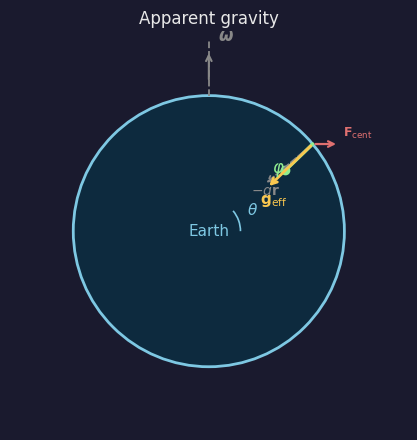

fig_apparent_gravity.png


In [3]:
def fig_apparent_gravity():
    fig, ax = plt.subplots(figsize=(4.5, 4.5), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_aspect('equal')
    ax.axis('off')

    # Earth circle
    earth = Circle((0, 0), 1.5, fill=True,
                   facecolor='#0d2a3e', edgecolor=BLUE, lw=2)
    ax.add_patch(earth)
    ax.text(0, 0, 'Earth', color=BLUE, ha='center', va='center', fontsize=11)

    # Rotation axis
    ax.plot([0, 0], [1.5, 2.1], '--', color=DIM, lw=1.3)
    ax.annotate('', xy=(0, 2.0), xytext=(0, 1.65),
                arrowprops=dict(arrowstyle='->', color=DIM, lw=1.5))
    ax.text(0.1, 2.1, r'$\boldsymbol{\omega}$', color=DIM, fontsize=12)

    # Latitude point on surface
    lat = np.radians(40)
    sx, sy = 1.5 * np.cos(lat), 1.5 * np.sin(lat)

    # True vertical (toward centre)
    vlen = 0.7
    vx = -sx / 1.5 * vlen
    vy = -sy / 1.5 * vlen
    ax.annotate('', xy=(sx + vx, sy + vy), xytext=(sx, sy),
                arrowprops=dict(arrowstyle='->', color=DIM, lw=1.3, linestyle='dashed'))
    ax.text(sx + vx - 0.15, sy + vy - 0.12, r'$-g\hat{\mathbf{r}}$',
            color=DIM, fontsize=10)

    # Centrifugal (outward, perpendicular to axis)
    cflen = 0.45
    cfx, cfy = np.sin(lat) * cflen, 0  # horizontal outward
    # but perpendicular to omega means in x-direction
    cfx = np.cos(np.radians(90) - lat) * cflen
    cfy = 0
    ax.annotate('', xy=(sx + cfx, sy), xytext=(sx, sy),
                arrowprops=dict(arrowstyle='->', color=RED, lw=1.6))
    ax.text(sx + cfx + 0.05, sy + 0.08, r'$\mathbf{F}_{\rm cent}$',
            color=RED, fontsize=9)

    # Effective gravity (sum)
    phi = np.radians(4)  # small deflection
    geff_angle = np.arctan2(sy, sx) + np.pi + phi
    gex = np.cos(geff_angle) * vlen
    gey = np.sin(geff_angle) * vlen
    ax.annotate('', xy=(sx + gex, sy + gey), xytext=(sx, sy),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2))
    ax.text(sx + gex - 0.08, sy + gey - 0.18,
            r'$\mathbf{g}_{\rm eff}$', color=YELLOW, fontsize=11)

    # Plumb line (along g_eff)
    ax.plot([sx, sx + gex * 0.6], [sy, sy + gey * 0.6],
            color=GREEN, lw=2.5, solid_capstyle='round')
    ax.plot(sx + gex * 0.6, sy + gey * 0.6,
            'o', color=GREEN, ms=6)

    # Angle phi label
    ax.text(sx - 0.45, sy - 0.32, r'$\varphi$', color=GREEN, fontsize=12)

    # Latitude label
    arc2 = Arc((0, 0), 0.7, 0.7, angle=0,
               theta1=0, theta2=np.degrees(lat),
               color=BLUE, lw=1.2)
    ax.add_patch(arc2)
    ax.text(0.42, 0.18, r'$\theta$', color=BLUE, fontsize=11)

    ax.set_title('Apparent gravity', color=WHITE, fontsize=12, pad=6)
    fig.tight_layout()
    fig.savefig('figures/fig_apparent_gravity.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('fig_apparent_gravity.png')

fig_apparent_gravity()


## Fig 3 — Rotating Bucket (§6.3)

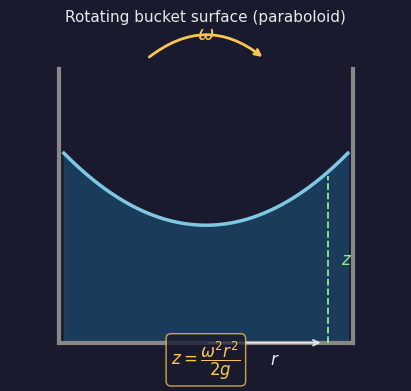

fig_rotating_bucket.png


In [4]:
def fig_rotating_bucket():
    fig, ax = plt.subplots(figsize=(4.5, 4.0), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-2.0, 2.0)
    ax.set_ylim(-0.3, 3.2)
    ax.set_aspect('equal')
    ax.axis('off')

    # Bucket walls
    ax.plot([-1.5, -1.5], [0, 2.8], color=DIM, lw=3)
    ax.plot([ 1.5,  1.5], [0, 2.8], color=DIM, lw=3)
    ax.plot([-1.5,  1.5], [0, 0],   color=DIM, lw=3)

    # Parabolic water surface
    r = np.linspace(-1.45, 1.45, 200)
    z0 = 1.2
    z = z0 + 0.35 * r**2
    ax.fill_between(r, 0.02, z, color='#1a4a6e', alpha=0.7)
    ax.plot(r, z, color=BLUE, lw=2.5)

    # omega arrow
    ax.annotate('', xy=(0.6, 2.9), xytext=(-0.6, 2.9),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2,
                                connectionstyle='arc3,rad=-0.4'))
    ax.text(0, 3.1, r'$\omega$', color=YELLOW, fontsize=14, ha='center')

    # r and z labels
    ax.annotate('', xy=(1.2, 0), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=1.3))
    ax.text(0.65, -0.22, r'$r$', color=WHITE, fontsize=12)

    z_at_r = z0 + 0.35 * 1.2**2
    ax.plot([1.25, 1.25], [0, z_at_r], '--', color=GREEN, lw=1.3)
    ax.text(1.38, z_at_r / 2, r'$z$', color=GREEN, fontsize=12, va='center')

    # Equation
    ax.text(0, -0.22, r'$z = \dfrac{\omega^2 r^2}{2g}$',
            color=YELLOW, fontsize=12, ha='center',
            bbox=dict(boxstyle='round', facecolor=DARK_BG,
                      edgecolor=YELLOW, alpha=0.8))

    ax.set_title('Rotating bucket surface (paraboloid)',
                 color=WHITE, fontsize=11, pad=6)
    fig.tight_layout()
    fig.savefig('figures/fig_rotating_bucket.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('fig_rotating_bucket.png')

fig_rotating_bucket()


## Fig 4 — Hurricane / Coriolis (§6.4.1)

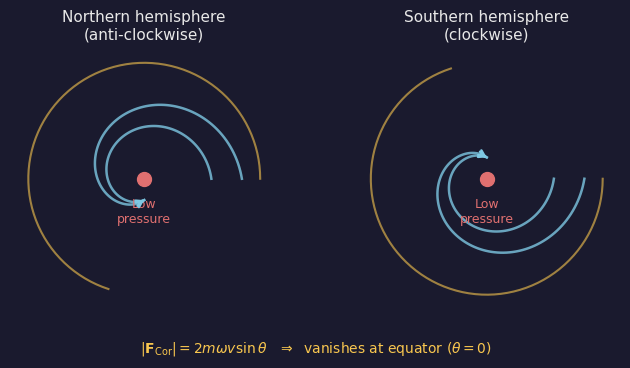

fig_hurricane.png


In [5]:
def fig_hurricane():
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), facecolor=DARK_BG)

    for ax in axes:
        base_style(ax)
        ax.set_xlim(-2.2, 2.2)
        ax.set_ylim(-2.2, 2.2)
        ax.set_aspect('equal')
        ax.axis('off')

    def draw_hurricane(ax, clockwise, title):
        # Low pressure centre
        ax.plot(0, 0, 'o', color=RED, ms=10, zorder=5)
        ax.text(0, -0.3, 'Low\npressure', color=RED,
                ha='center', fontsize=9, va='top')

        # Spiral arrows
        sign = -1 if clockwise else 1
        for r0 in [1.6, 1.1]:
            t = np.linspace(0, sign * 1.5 * np.pi, 120)
            r = np.linspace(r0, 0.35, 120)
            x = r * np.cos(t)
            y = r * np.sin(t)
            ax.plot(x, y, color=BLUE, lw=1.8, alpha=0.8)
            # Arrowhead at end
            ax.annotate('',
                        xy=(x[-1], y[-1]),
                        xytext=(x[-3], y[-3]),
                        arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.8))

        # Rotation arrow around perimeter
        theta_arr = np.linspace(0, sign * 1.4 * np.pi, 80)
        ax.plot(1.9 * np.cos(theta_arr), 1.9 * np.sin(theta_arr),
                color=YELLOW, lw=1.5, alpha=0.6)

        ax.set_title(title, color=WHITE, fontsize=11, pad=4)

    draw_hurricane(axes[0], clockwise=False,
                   title='Northern hemisphere\n(anti-clockwise)')
    draw_hurricane(axes[1], clockwise=True,
                   title='Southern hemisphere\n(clockwise)')

    # Latitude factor annotation
    fig.text(0.5, 0.01,
             r'$|\mathbf{F}_{\rm Cor}| = 2m\omega v\sin\theta$  '
             r'$\;\Rightarrow\;$ vanishes at equator ($\theta=0$)',
             color=YELLOW, ha='center', fontsize=10)

    fig.tight_layout(rect=[0, 0.08, 1, 1])
    fig.savefig('figures/fig_hurricane.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('fig_hurricane.png')

fig_hurricane()


## Fig 5 — Foucault's Pendulum (§6.4.3)

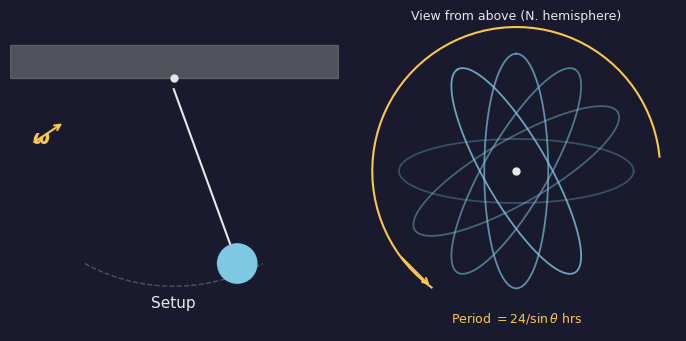

fig_foucault.png


In [6]:
def fig_foucault():
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), facecolor=DARK_BG)

    # Left: pendulum setup
    ax = axes[0]
    base_style(ax)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-2.0, 0.5)
    ax.set_aspect('equal')
    ax.axis('off')

    # Ceiling
    ax.fill_between([-1.5, 1.5], [0.1, 0.1], [0.4, 0.4], color=DIM, alpha=0.5)
    ax.plot(0, 0.1, 'o', color=WHITE, ms=5)

    # Pendulum string and bob
    bob_angle = np.radians(20)
    L = 1.7
    bx = L * np.sin(bob_angle)
    by = -L * np.cos(bob_angle)
    ax.plot([0, bx], [0, by], color=WHITE, lw=1.5)
    bob = Circle((bx, by), 0.18, color=BLUE, zorder=5)
    ax.add_patch(bob)

    # Oscillation plane indicator (faint ellipse trace)
    t = np.linspace(-0.5, 0.5, 100)
    ax.plot(L * np.sin(t), -L * np.cos(t) + L * np.cos(t[0]) + by,
            '--', color=DIM, lw=1, alpha=0.5)

    # Omega label
    ax.text(-1.3, -0.5, r'$\boldsymbol{\omega}$', color=YELLOW, fontsize=14)
    ax.annotate('', xy=(-1.0, -0.3), xytext=(-1.3, -0.5),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5))

    ax.text(0, -2.0, 'Setup', color=WHITE, fontsize=11, ha='center')

    # Right: rotating plane viewed from above
    ax2 = axes[1]
    base_style(ax2)
    ax2.set_xlim(-1.5, 1.5)
    ax2.set_ylim(-1.5, 1.5)
    ax2.set_aspect('equal')
    ax2.axis('off')

    # Multiple ellipses at different rotation angles (viewed from above)
    for phi_deg in range(0, 150, 30):
        phi = np.radians(phi_deg)
        t = np.linspace(0, 2 * np.pi, 200)
        a, b = 1.1, 0.3
        x = a * np.cos(t) * np.cos(phi) - b * np.sin(t) * np.sin(phi)
        y = a * np.cos(t) * np.sin(phi) + b * np.sin(t) * np.cos(phi)
        alpha = 0.3 + 0.5 * (phi_deg / 120)
        ax2.plot(x, y, color=BLUE, lw=1.3, alpha=alpha)

    # Centre dot
    ax2.plot(0, 0, 'o', color=WHITE, ms=5)

    # Rotation arrow
    t_arr = np.linspace(0.1, 1.3 * np.pi, 60)
    ax2.plot(1.35 * np.cos(t_arr), 1.35 * np.sin(t_arr),
             color=YELLOW, lw=1.5)
    ax2.annotate('', xy=(1.35 * np.cos(1.3 * np.pi),
                         1.35 * np.sin(1.3 * np.pi)),
                 xytext=(1.35 * np.cos(1.2 * np.pi),
                         1.35 * np.sin(1.2 * np.pi)),
                 arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5))

    ax2.text(0, -1.42, r'Period $= 24/\sin\theta$ hrs',
             color=YELLOW, ha='center', fontsize=9)

    ax2.text(0, 1.42, 'View from above (N. hemisphere)',
             color=WHITE, ha='center', fontsize=9)

    fig.tight_layout()
    fig.savefig('figures/fig_foucault.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('fig_foucault.png')

fig_foucault()


## Download all figures

In [7]:
import shutil
from google.colab import files
shutil.make_archive('figures', 'zip', '.', 'figures')
files.download('figures.zip')
print('figures.zip downloaded')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

figures.zip downloaded
